# Phần 3: Dự báo PM2.5 trung bình theo ngày bằng ARIMA

# I. Import thư viện

In [3]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# II. Đọc dữ liệu và gộp theo ngày

In [4]:
df = pd.read_csv("Data/hanoi-aqi-weather-data.csv", parse_dates=["Local Time"], index_col="Local Time")
df.head()

,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
Local Time,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,2023-03-07T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,131,170.6,29.3,53.3,58.8,47.0,67.3,91,0.0,1016,86,21.2,0.0,2.00
2023-03-08 01:00:00,2023-03-07T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,158.7,25.0,54.0,56.3,45.0,65.0,100,0.0,1016,89,21.1,0.0,2.00
2023-03-08 02:00:00,2023-03-07T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,150.2,21.7,55.0,52.5,42.0,65.7,100,0.0,1016,90,20.9,0.0,1.66
2023-03-08 03:00:00,2023-03-07T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,141.6,18.3,56.0,56.3,45.0,66.3,100,0.0,1016,91,20.7,0.0,1.33
2023-03-08 04:00:00,2023-03-07T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,133.1,15.0,57.0,52.5,42.0,67.0,100,0.0,1015,92,20.5,0.0,1.00


**Ý nghĩa các cột trong dữ liệu** (8.785 dòng, mỗi dòng là một giờ)

| Nhóm | Cột | Ý nghĩa | Đơn vị |
|---|---|---|---|
| Thời gian & vị trí | `Local Time` | Thời điểm đo theo giờ Hà Nội, dùng làm chỉ mục | giờ (UTC+7) |
| | `UTC Time` | Cùng thời điểm đó theo giờ UTC | giờ (UTC) |
| | `City`, `Country Code`, `Timezone` | Thành phố (Hanoi), mã quốc gia (VN), múi giờ (Asia/Ho_Chi_Minh); không đổi trong cả bộ dữ liệu | – |
| Chất lượng không khí | `AQI` | Chỉ số chất lượng không khí theo chuẩn US EPA, càng cao càng ô nhiễm | 0–500 |
| | `PM25` | Nồng độ bụi mịn đường kính nhỏ hơn 2,5 µm. Đây là biến cần dự báo ở Part 3 | µg/m³ |
| | `PM10` | Nồng độ bụi đường kính nhỏ hơn 10 µm (gồm cả PM2.5) | µg/m³ |
| | `CO` | Nồng độ khí carbon monoxide | µg/m³ |
| | `NO2` | Nồng độ nitơ dioxide (chủ yếu từ giao thông, đốt nhiên liệu) | µg/m³ |
| | `SO2` | Nồng độ lưu huỳnh dioxide (chủ yếu từ đốt than, dầu) | µg/m³ |
| | `O3` | Nồng độ ozone mặt đất | µg/m³ |
| Thời tiết | `Temperature` | Nhiệt độ không khí | °C |
| | `Relative Humidity` | Độ ẩm tương đối | % |
| | `Pressure` | Áp suất khí quyển | hPa |
| | `Wind Speed` | Tốc độ gió | m/s |
| | `Precipitation` | Lượng mưa trong giờ | mm |
| | `Clouds` | Độ che phủ của mây | % |
| | `UV Index` | Chỉ số tia cực tím | không có đơn vị |

Trong Part 3 chỉ dùng `Local Time` và `PM25`; các cột còn lại phục vụ Part 2 và các hướng mở rộng (ví dụ thêm biến thời tiết vào mô hình).

In [5]:
# Trung bình PM2.5 mỗi ngày
daily = df["PM25"].resample("D").mean()
daily.name = "PM2.5"

print("Số ngày:", len(daily), "| từ", daily.index.min().date(), "đến", daily.index.max().date())
print("Ngày thiếu dữ liệu:", int(daily.isna().sum()))
daily.describe().round(2)

Số ngày: 367 | từ 2023-03-08 đến 2024-03-08
Ngày thiếu dữ liệu: 0


,PM2.5
count,367.00
mean,49.43
std,39.59
min,2.33
25%,27.59
50%,38.48
75%,54.94
max,261.01


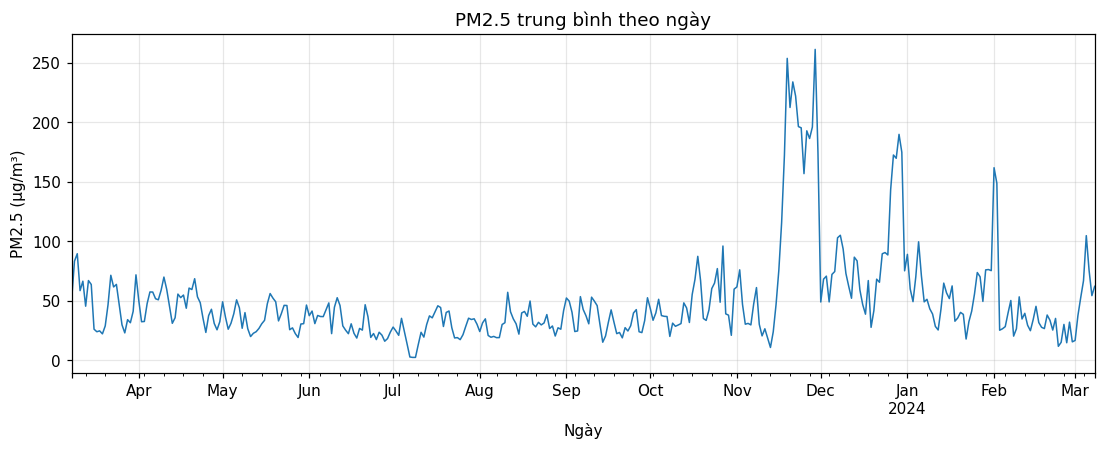

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
daily.plot(ax=ax, lw=1)
ax.set_title("PM2.5 trung bình theo ngày")
ax.set_xlabel("Ngày")
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

# III. Chia tập huấn luyện và kiểm tra (80/20 theo thời gian)

Train: 293 ngày (2023-03-08 -> 2023-12-25), TB = 47.6
Test : 74 ngày (2023-12-26 -> 2024-03-08), TB = 56.5


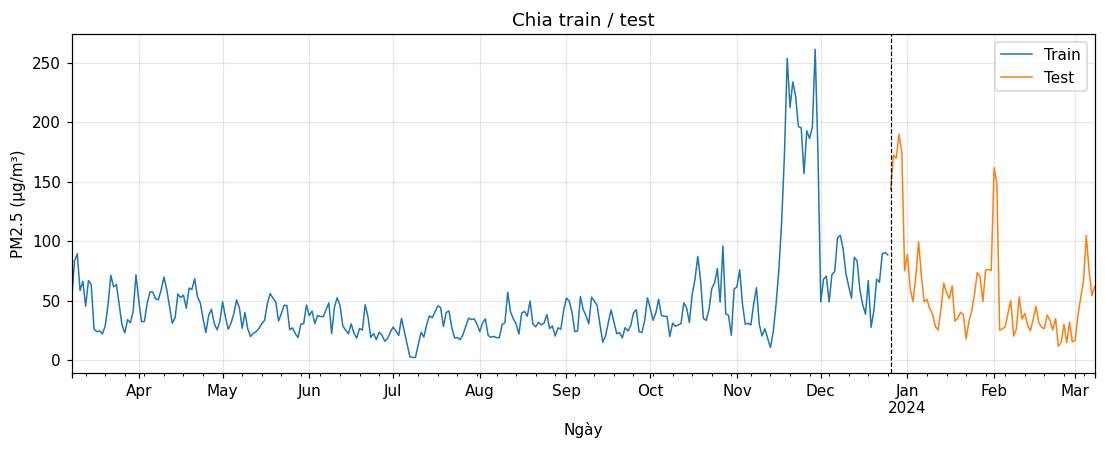

In [7]:
n_train = int(len(daily) * 0.8)
train, test = daily.iloc[:n_train], daily.iloc[n_train:]

print(f"Train: {len(train)} ngày ({train.index[0].date()} -> {train.index[-1].date()}), TB = {train.mean():.1f}")
print(f"Test : {len(test)} ngày ({test.index[0].date()} -> {test.index[-1].date()}), TB = {test.mean():.1f}")

fig, ax = plt.subplots(figsize=(12, 4))
train.plot(ax=ax, label="Train", lw=1)
test.plot(ax=ax, label="Test", lw=1)
ax.axvline(test.index[0], color="k", ls="--", lw=0.8)
ax.set_title("Chia train / test")
ax.set_xlabel("Ngày")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.show()

# IV. Kiểm định tính dừng (ADF) trên tập train

**Kiểm định tính dừng (ADF) trên tập train**

- **Chuỗi dừng là gì:** chuỗi có trung bình, phương sai và mức độ tự tương quan không đổi theo thời gian (dao động quanh một mức ổn định). Chuỗi có xu hướng tăng/giảm dài hạn hoặc mức nền trôi đi là chuỗi không dừng.
- **Vì sao cần kiểm tra:** ARIMA giả định chuỗi dừng sau khi lấy sai phân. Nếu chuỗi gốc không dừng thì phải lấy sai phân (d ≥ 1), tức mô hình dự báo *mức thay đổi so với hôm qua* thay vì mức PM2.5 tuyệt đối. Giá trị d này chính là tham số d trong ARIMA(p, d, q).
- **Kiểm định ADF (Augmented Dickey-Fuller):**
  - Giả thuyết H0: chuỗi **không dừng** (có nghiệm đơn vị).
  - Nếu p < 0,05 thì bác bỏ H0 → coi chuỗi **dừng**. Nếu p ≥ 0,05 thì chưa đủ bằng chứng để nói chuỗi dừng.
  - `autolag="AIC"`: tự chọn số độ trễ trong phép kiểm định bằng AIC.
- **Vì sao chỉ làm trên tập train:** d là một quyết định về mô hình, nên chỉ được dựa vào dữ liệu train (xem lại mục III về rò rỉ dữ liệu).
- **Cách đọc kết quả:**
  - Chuỗi gốc: ADF = -2,612, p = 0,0905 → **không dừng** (p > 0,05).
  - Sau sai phân bậc 1: ADF = -6,256, p ≈ 0 → **dừng**.
  - Vậy chọn **d = 1**, và dùng D = 1 ở bước tìm tham số (mục VII).
- **Lưu ý:** p = 0,09 chỉ hơi vượt ngưỡng 0,05, nên kết luận "không dừng" không quá chắc chắn (chuỗi gộp cả năm thì p = 0,0009, tức dừng). ADF cũng có thể thay đổi theo cách chia dữ liệu. Vì chuỗi này có mùa (đông cao hơn hẳn) nên lấy sai phân là lựa chọn an toàn, và ACF sau sai phân (mục V) không còn suy giảm chậm như chuỗi gốc, cho thấy sai phân bậc 1 đã đủ.

In [8]:
def adf_report(series, name):
    stat, p, *_ = adfuller(series.dropna(), autolag="AIC")
    kq = "dừng" if p < 0.05 else "KHÔNG dừng"
    print(f"{name:<28} ADF = {stat:7.3f} | p = {p:.4f} -> {kq}")

adf_report(train, "Train (gốc)")
adf_report(train.diff(), "Train (sai phân bậc 1)")

Train (gốc)                  ADF =  -2.612 | p = 0.0905 -> KHÔNG dừng
Train (sai phân bậc 1)       ADF =  -6.256 | p = 0.0000 -> dừng


# V. ACF và PACF trên tập train

**ACF và PACF trên tập train**

- **ACF (hàm tự tương quan):** tương quan giữa PM2.5 hôm nay và PM2.5 cách đây k ngày (lag k). Giá trị gồm cả ảnh hưởng *gián tiếp*: hôm nay giống hôm kia một phần vì cả hai cùng giống hôm qua.
- **PACF (hàm tự tương quan riêng phần):** cũng là tương quan với lag k nhưng đã loại ảnh hưởng của các lag trung gian (1 đến k-1), chỉ giữ phần ảnh hưởng *trực tiếp*.
- **Vùng xanh:** khoảng tin cậy 95% quanh 0. Cột nằm trong vùng xanh coi như không khác 0 (nhiễu); cột vượt ra ngoài là tương quan có ý nghĩa thống kê. Với 30 lag thì vẫn có thể có 1–2 cột vượt ra ngoài chỉ do ngẫu nhiên.
- **Dùng để làm gì:** gợi ý ban đầu cho bậc p (AR) và q (MA) của ARIMA:
  - PACF cắt đột ngột sau lag p, ACF giảm dần → gợi ý AR(p).
  - ACF cắt đột ngột sau lag q, PACF giảm dần → gợi ý MA(q).
  - Cả hai đều giảm dần → có thể cần cả AR và MA.
  Đây chỉ là gợi ý; tham số cuối cùng được chọn bằng AIC ở mục VII.
- **Vì sao vẽ cả chuỗi gốc lẫn sai phân bậc 1:** chuỗi gốc cho thấy vì sao cần lấy sai phân; chuỗi sai phân (d = 1, theo mục IV) mới là chuỗi dùng để đọc p và q.
- **Chỉ tính trên tập train** để không dùng thông tin của test.
- **Cách đọc kết quả:**
  - *Chuỗi gốc:* ACF bắt đầu ở khoảng 0,9 và giảm rất chậm, vẫn vượt vùng xanh đến khoảng lag 11. Đây là dấu hiệu điển hình của chuỗi không dừng, khớp với kết quả ADF. PACF chỉ có lag 1 nổi bật (≈ 0,9), các lag sau gần như nằm trong vùng xanh: PM2.5 hôm nay phụ thuộc trực tiếp chủ yếu vào hôm qua.
  - *Sau sai phân:* hầu hết các cột nằm trong vùng xanh, giống nhiễu trắng. Nghĩa là sau khi trừ đi giá trị hôm qua, phần thay đổi còn lại gần như không đoán được từ quá khứ, nên mô hình phù hợp là mô hình bậc thấp.
  - Có một cột âm ở lag 12–13 (khoảng -0,2) ở cả ACF và PACF. Chưa có cơ sở để gán cho một chu kỳ cụ thể, nên không đưa thêm tham số mùa vào mô hình.
- **Liên hệ với các bước sau:** kết quả này khớp với việc AIC chọn ARIMA(1,1,1) và với việc ARIMA chỉ hơn baseline "hôm nay = hôm qua" rất ít (mục VI, IX).
- **Lưu ý:** trục hoành là số ngày (dữ liệu đã gộp theo ngày), không phải giờ.

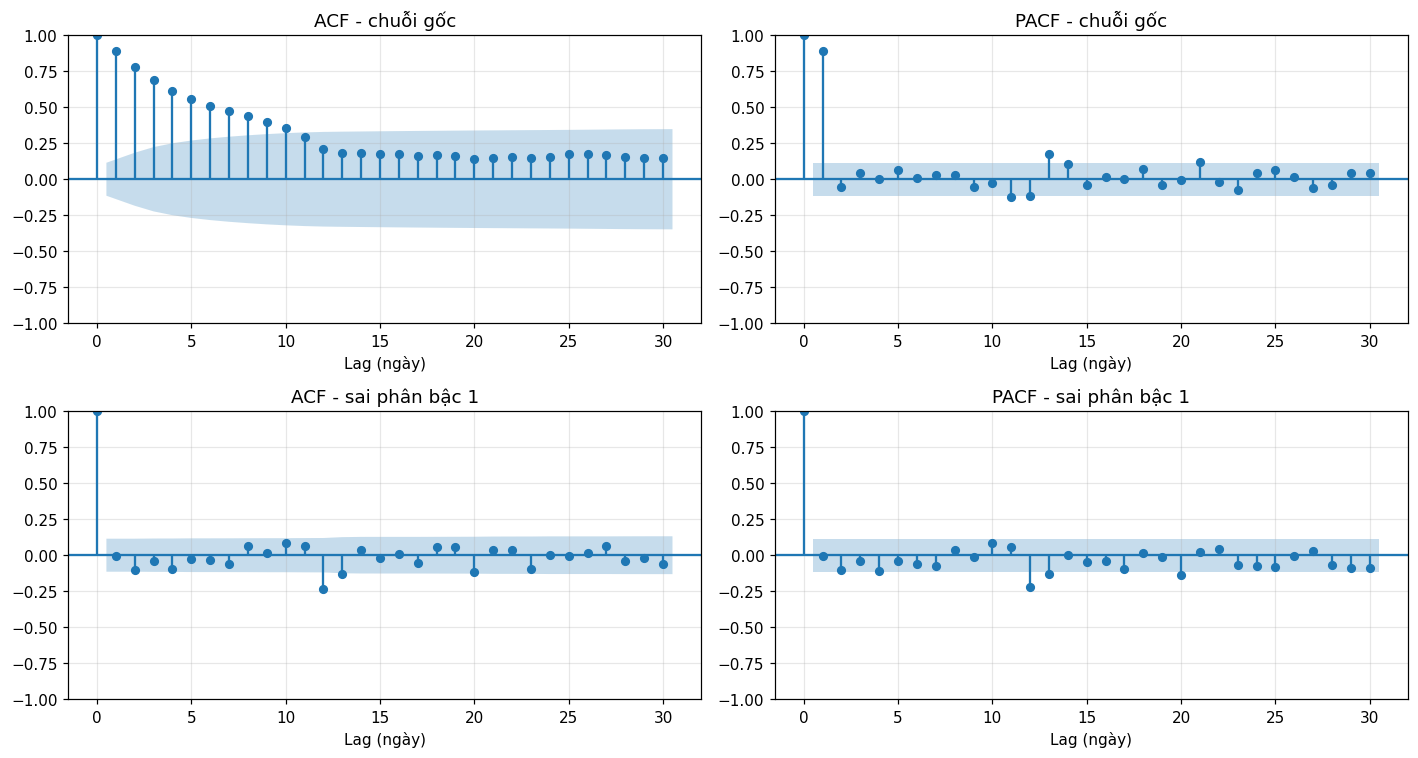

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(train, lags=30, ax=ax[0, 0], title="ACF - chuỗi gốc")
plot_pacf(train, lags=30, ax=ax[0, 1], title="PACF - chuỗi gốc", method="ywm")
plot_acf(train.diff().dropna(), lags=30, ax=ax[1, 0], title="ACF - sai phân bậc 1")
plot_pacf(train.diff().dropna(), lags=30, ax=ax[1, 1], title="PACF - sai phân bậc 1", method="ywm")
for a in ax.ravel():
    a.set_xlabel("Lag (ngày)")
plt.tight_layout()
plt.show()

**Nhận xét**

- **ACF chuỗi gốc:** bắt đầu ở khoảng 0,9 tại lag 1 rồi giảm rất chậm (≈ 0,78 ở lag 2, ≈ 0,56 ở lag 5, ≈ 0,36 ở lag 10), vượt vùng tin cậy đến khoảng lag 10–11. Các lag sau vẫn dương nhẹ (≈ 0,15). Đường giảm chậm như vậy là dấu hiệu của chuỗi không dừng, khớp với ADF ở mục IV.
- **PACF chuỗi gốc:** chỉ lag 1 nổi bật (≈ 0,9), các lag còn lại gần như nằm trong vùng xanh. Một vài cột nhỏ chạm hoặc vượt nhẹ vùng xanh (lag 11–13, lag 21) nhưng độ lớn thấp (khoảng ±0,1–0,17) và không theo quy luật rõ ràng. Nghĩa là PM2.5 hôm nay phụ thuộc trực tiếp chủ yếu vào PM2.5 hôm qua; các ngày xa hơn chỉ ảnh hưởng gián tiếp qua hôm qua.
- **ACF và PACF sau sai phân bậc 1:** gần như toàn bộ các cột nằm trong vùng xanh, và lag 1 xấp xỉ 0. Phần thay đổi PM2.5 giữa hai ngày liên tiếp gần giống nhiễu trắng, tức không dự đoán được từ các thay đổi trước đó. Không có tín hiệu rõ ràng cho AR hay MA bậc cao.
- **Điểm bất thường duy nhất:** cột âm ở lag 12 (≈ -0,23 ở ACF, ≈ -0,22 ở PACF) vượt vùng xanh rõ, kèm lag 13 (≈ -0,13) vượt nhẹ. Với 30 lag thì vài cột vượt ngưỡng do ngẫu nhiên là bình thường, và không có lý do vật lý nào cho chu kỳ 12 ngày, nên không đưa thành phần mùa vào mô hình.
- **Kết luận:** chuỗi cần d = 1, sau đó chỉ cần mô hình bậc thấp (p, q ≤ 1–2). Điều này phù hợp với việc AIC chọn ARIMA(1,1,1) ở mục VII. Nó cũng báo trước rằng mô hình sẽ gần như dự báo "ngày mai ≈ hôm nay", nên khó hơn hẳn baseline "hôm qua" (kết quả ở mục IX).

# VI. Mô hình cơ sở (baseline) trên tập test

In [10]:
def metrics(actual, pred):
    return {
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
    }

# Baseline 1: luôn dự đoán bằng trung bình train
pred_mean = pd.Series(train.mean(), index=test.index)

# Baseline 2: hôm nay = hôm qua (ngày đầu của test lấy ngày cuối của train)
pred_persist = daily.shift(1).loc[test.index]

results = pd.DataFrame({
    "Trung bình train": metrics(test, pred_mean),
    "Hôm nay = hôm qua": metrics(test, pred_persist),
}).T.round(2)
results

,MAE,RMSE
Trung bình train,27.21,41.75
Hôm nay = hôm qua,17.48,26.99


# VII. Chọn tham số ARIMA(p, d, q) bằng AIC

In [11]:
D = 1  # theo kết quả ADF ở mục IV
rows = []
for p in range(0, 8):
    for q in range(0, 3):
        try:
            res = ARIMA(train, order=(p, D, q)).fit()
            fitted = res.fittedvalues.iloc[D:]
            rows.append({
                "p": p, "d": D, "q": q,
                "AIC": res.aic, "BIC": res.bic,
                "MAE_train": mean_absolute_error(train.iloc[D:], fitted),
            })
        except Exception as e:
            print("Lỗi", (p, D, q), e)

grid = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
best = grid.iloc[0]
ORDER = (int(best.p), int(best.d), int(best.q))
print("Mô hình chọn theo AIC: ARIMA%s" % (ORDER,))
grid.head(8).round(2)

Mô hình chọn theo AIC: ARIMA(1, 1, 1)


,p,d,q,AIC,BIC,MAE_train
0,1,1,1,2514.72,2525.75,11.58
1,1,1,2,2515.27,2529.97,11.59
2,2,1,1,2515.37,2530.08,11.59
3,2,1,2,2516.64,2535.03,11.56
4,3,1,1,2517.10,2535.49,11.58
5,3,1,2,2518.64,2540.70,11.56
6,4,1,1,2518.92,2540.98,11.58
7,5,1,1,2520.12,2545.85,11.50


In [12]:
# Đối chiếu với lựa chọn theo BIC và theo MAE train
by_bic = grid.sort_values("BIC").iloc[0]
by_mae = grid.sort_values("MAE_train").iloc[0]
print("Theo BIC      : ARIMA(%d,%d,%d)" % (by_bic.p, by_bic.d, by_bic.q))
print("Theo MAE train: ARIMA(%d,%d,%d)" % (by_mae.p, by_mae.d, by_mae.q))

Theo BIC      : ARIMA(1,1,1)
Theo MAE train: ARIMA(5,1,1)


# VIII. Chẩn đoán phần dư

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8636      0.034     25.719      0.000       0.798       0.929
ma.L1         -0.9779      0.016    -60.748      0.000      -1.009      -0.946
sigma2       314.5197     12.435     25.292      0.000     290.147     338.893


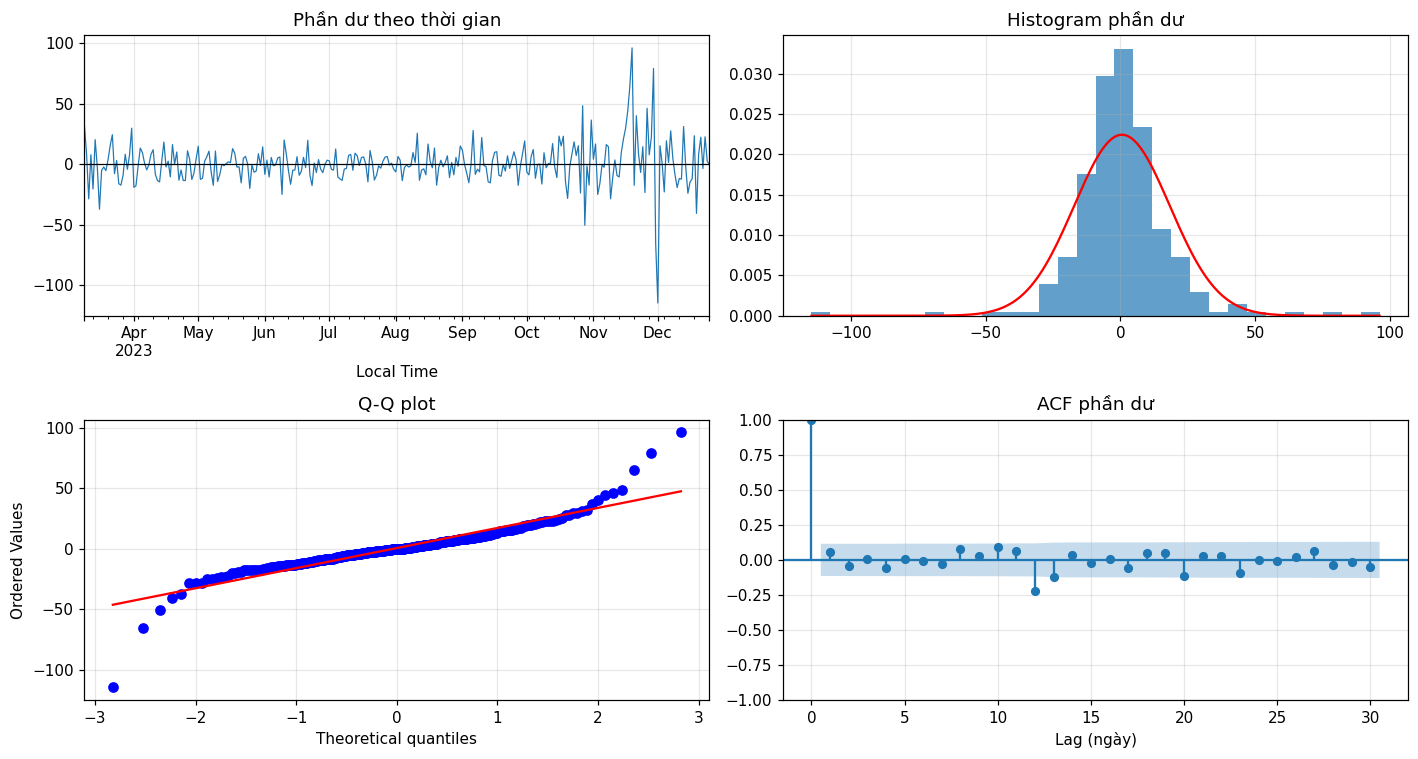

In [13]:
model = ARIMA(train, order=ORDER).fit()
print(model.summary().tables[1])
resid = model.resid.iloc[D:]

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
resid.plot(ax=ax[0, 0], lw=0.8, title="Phần dư theo thời gian")
ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 1].hist(resid, bins=30, density=True, alpha=0.7)
xs = np.linspace(resid.min(), resid.max(), 200)
ax[0, 1].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), "r")
ax[0, 1].set_title("Histogram phần dư")
stats.probplot(resid, dist="norm", plot=ax[1, 0])
ax[1, 0].set_title("Q-Q plot")
plot_acf(resid, lags=30, ax=ax[1, 1], title="ACF phần dư")
ax[1, 1].set_xlabel("Lag (ngày)")
plt.tight_layout()
plt.show()

**Nhận xét**

- **Phần dư theo thời gian:** dao động quanh 0 và không có xu hướng, nhưng độ lớn không đồng đều. Từ tháng 3 đến khoảng tháng 10, phần dư hầu như nằm trong ±25 µg/m³. Từ cuối tháng 10 đến tháng 12 biên độ tăng mạnh: đỉnh dương khoảng +96 (giữa tháng 11) và đáy âm khoảng -114 (cuối tháng 11). Phương sai của phần dư tăng theo mùa đông, tức giả định phương sai không đổi bị vi phạm.
- **Histogram:** tập trung quanh 0 và gần đối xứng (độ lệch ≈ 0), nhưng đỉnh nhọn hơn đường chuẩn (màu đỏ) và có đuôi dày ở cả hai phía, với vài giá trị cực trị ngoài ±60. Phần lớn ngày mô hình sai ít, một số ít ngày sai rất lớn.
- **Q-Q plot:** phần giữa nằm sát đường thẳng, nhưng hai đầu lệch xa (điểm thấp nhất khoảng -114, điểm cao nhất khoảng +96). Phần dư **không chuẩn** do đuôi nặng, khớp với Shapiro-Wilk p ≈ 0.
- **ACF phần dư:** hầu hết các cột nằm trong vùng xanh nên mô hình đã khai thác gần hết tự tương quan ngắn hạn. Ngoại lệ là lag 12 (≈ -0,22, vượt rõ) và lag 13 (≈ -0,12), lặp lại đúng điểm bất thường đã thấy ở mục V. Ljung-Box cho p = 0,68 ở lag 10 (không còn tự tương quan) nhưng p = 0,021 ở lag 20, chủ yếu do lag 12.
- **Kết luận:** ARIMA(1,1,1) đủ để bắt phần tự tương quan chính của chuỗi, nên dự báo điểm vẫn dùng được. Hạn chế là phần dư không chuẩn và phương sai tăng vào mùa đông, nên khoảng tin cậy và p-value của hệ số kém tin cậy, và sai số lớn tập trung vào các đợt ô nhiễm đột biến. Có thể xem xét biến đổi log PM2.5 trước khi mô hình hóa để ổn định phương sai.

In [14]:
lb = acorr_ljungbox(resid, lags=[10, 20], return_df=True)
print("Ljung-Box (H0: phần dư không tự tương quan)")
print(lb.round(4))
print("Shapiro-Wilk p =", round(stats.shapiro(resid).pvalue, 4), "| độ lệch =", round(stats.skew(resid), 2))

Ljung-Box (H0: phần dư không tự tương quan)
    lb_stat  lb_pvalue
10   7.4430     0.6831
20  34.8566     0.0209
Shapiro-Wilk p = 0.0 | độ lệch = -0.01


# IX. Walk-forward: dự báo 1 ngày trên tập test

In [15]:
history = list(train.values)
preds = []
for i, actual in enumerate(test.values):
    fit = ARIMA(history, order=ORDER).fit()
    preds.append(fit.forecast(1)[0])
    history.append(actual)   # thêm giá trị thật của ngày vừa dự báo

pred_arima = pd.Series(preds, index=test.index)

results.loc["ARIMA%s" % (ORDER,)] = pd.Series(metrics(test, pred_arima)).round(2)
results

,MAE,RMSE
Trung bình train,27.21,41.75
Hôm nay = hôm qua,17.48,26.99
"ARIMA(1, 1, 1)",17.88,26.78


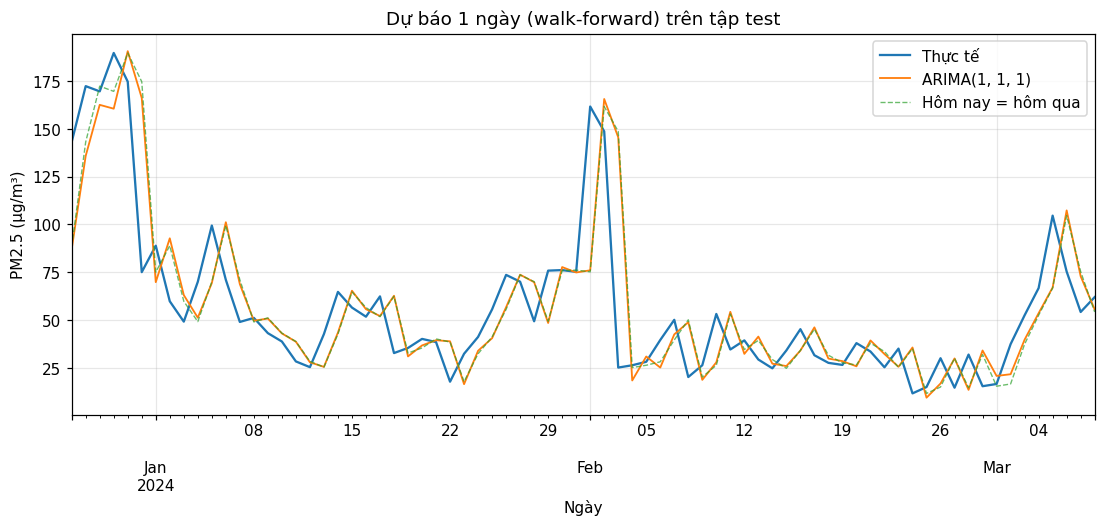

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.5))
test.plot(ax=ax, label="Thực tế", lw=1.5)
pred_arima.plot(ax=ax, label="ARIMA%s" % (ORDER,), lw=1.2)
pred_persist.plot(ax=ax, label="Hôm nay = hôm qua", lw=0.9, ls="--", alpha=0.7)
ax.set_title("Dự báo 1 ngày (walk-forward) trên tập test")
ax.set_xlabel("Ngày")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.show()

**Nhận xét**

- **Hai đường dự báo gần như trùng nhau:** đường ARIMA(1,1,1) (cam) và đường "hôm nay = hôm qua" (xanh lá đứt nét) chồng khít trên hầu hết các ngày. ARIMA gần như chỉ sao chép giá trị của ngày hôm trước, đúng với nhận xét ở mục V và VIII (mô hình gần với dạng "ngày mai ≈ hôm nay").
- **Dự báo luôn trễ một ngày so với thực tế:** mỗi đỉnh hoặc đáy của đường thực tế (xanh dương) đều xuất hiện ở đường dự báo vào ngày kế tiếp. Ví dụ đỉnh khoảng 190 µg/m³ vào cuối tháng 12 và đỉnh khoảng 160 vào đầu tháng 2 đều bị dự báo chậm một ngày. Mô hình chỉ phản ứng sau khi biến động đã xảy ra, không báo trước được.
- **Sai số lớn nhất rơi vào các ngày đột biến:** ngày PM2.5 tăng vọt từ khoảng 76 lên khoảng 160 (đầu tháng 2), và ngày giảm mạnh từ khoảng 150 xuống khoảng 25 ngay sau đó, dự báo lệch hàng chục đơn vị. Khoảng cuối tháng 12 cũng có đợt giảm từ khoảng 175 xuống khoảng 75 với sai lệch tương tự.
- **Giai đoạn ổn định thì bám tốt:** khi PM2.5 dao động nhẹ quanh 25–75 (giữa tháng 1, cuối tháng 2), sai số chỉ vài đơn vị đến khoảng 10 µg/m³.
- **Về mặt định lượng:** MAE của ARIMA là 17,88, còn baseline "hôm qua" là 17,48 (thấp hơn không đáng kể). ARIMA sai ít hơn ở 36/74 ngày, kiểm định Wilcoxon p = 0,30, nên khác biệt không có ý nghĩa thống kê. Cả hai đều tốt hơn rõ rệt baseline trung bình (MAE 27,21).
- **Kết luận:** việc đường dự báo "khớp" thực tế trên biểu đồ phần lớn do cả hai đều bám theo giá trị hôm qua, không phải do mô hình nắm được quy luật biến động. Mô hình hữu ích cho dự báo 1 ngày khi chuỗi ổn định, nhưng không dự báo được các đợt tăng hoặc giảm đột ngột của mùa đông.

In [17]:
# ARIMA hơn baseline "hôm qua" bao nhiêu, và hơn ở bao nhiêu ngày?
err_arima = (test - pred_arima).abs()
err_persist = (test - pred_persist).abs()

mae_a, mae_p = err_arima.mean(), err_persist.mean()
print(f"MAE ARIMA: {mae_a:.2f} | MAE hôm qua: {mae_p:.2f} | ARIMA thấp hơn {100*(mae_p-mae_a)/mae_p:.1f}%")
print(f"Số ngày ARIMA sai ít hơn: {(err_arima < err_persist).sum()}/{len(test)}")

# Kiểm định cặp (Wilcoxon) trên sai số tuyệt đối từng ngày
print("Wilcoxon p =", round(stats.wilcoxon(err_arima, err_persist).pvalue, 4))

MAE ARIMA: 17.88 | MAE hôm qua: 17.48 | ARIMA thấp hơn -2.3%
Số ngày ARIMA sai ít hơn: 36/74
Wilcoxon p = 0.2997


# X. Dự báo nhiều ngày (1 đến 7 ngày)

In [18]:
H = 7
values = daily.values
n0 = len(train)
err = {"ARIMA": [], "Hôm qua": [], "Trung bình train": []}

# Mỗi ngày trong test làm một mốc dự báo: dùng dữ liệu đến hôm trước, dự báo H ngày tiếp theo.
# Chỉ giữ mốc còn đủ H ngày thực tế phía sau.
for i in range(len(test) - H + 1):
    t = n0 + i
    fit = ARIMA(values[:t], order=ORDER).fit()
    f = fit.forecast(H)
    actual = values[t:t + H]
    err["ARIMA"].append(np.abs(actual - f))
    err["Hôm qua"].append(np.abs(actual - values[t - 1]))
    err["Trung bình train"].append(np.abs(actual - train.mean()))

mae_h = pd.DataFrame({k: np.mean(v, axis=0) for k, v in err.items()}, index=range(1, H + 1))
mae_h.index.name = "Số ngày dự báo trước"
mae_h.round(2)

,ARIMA,Hôm qua,Trung bình train
Số ngày dự báo trước,,,
1,17.69,17.18,27.71
2,24.87,24.60,26.38
3,26.74,27.14,24.82
4,28.88,30.41,23.87
5,29.96,32.06,22.19
6,29.35,31.97,20.42
7,32.20,34.87,20.22


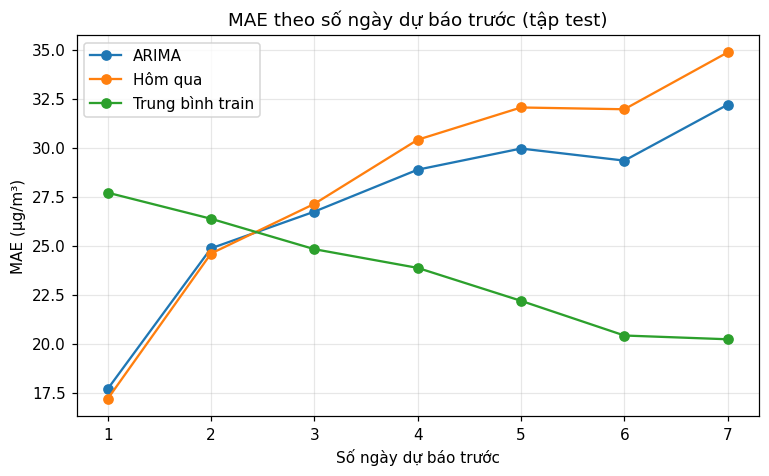

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
mae_h.plot(ax=ax, marker="o")
ax.set_title("MAE theo số ngày dự báo trước (tập test)")
ax.set_xlabel("Số ngày dự báo trước")
ax.set_ylabel("MAE (µg/m³)")
plt.show()

**Nhận xét**

- **Sai số của ARIMA tăng nhanh theo số ngày dự báo trước:** từ khoảng 17,7 µg/m³ ở 1 ngày lên khoảng 24,9 ở 2 ngày, rồi khoảng 32,2 ở 7 ngày (tăng gần 80%). Bước nhảy lớn nhất là từ ngày 1 sang ngày 2 (+7). Càng dự báo xa thì thông tin của hôm nay càng ít giá trị, vì PM2.5 thay đổi nhanh theo thời tiết (ACF giảm dần theo lag, mục V).
- **ARIMA so với baseline "hôm qua":** hai đường gần như trùng nhau ở ngày 1 và 2 (chênh dưới 0,6). Từ ngày 3 trở đi, ARIMA thấp hơn và khoảng cách rộng dần (ngày 7: 32,2 so với 34,9). Có thể do ARIMA làm mượt giá trị hôm qua thay vì giữ nguyên, nên bớt sai hơn khi dự báo xa. Chênh lệch tối đa chỉ khoảng 2–3 µg/m³ và chưa được kiểm định thống kê.
- **Baseline trung bình train đổi chiều:** ở ngày 1 và 2 nó kém ARIMA (27,7 và 26,4), nhưng từ ngày 3 trở đi nó thấp hơn cả ARIMA lẫn "hôm qua" (24,8 ở ngày 3, xuống khoảng 20,2 ở ngày 7). Đường ARIMA cắt đường trung bình trong khoảng ngày 2–3.
- **Cẩn thận khi đọc đường trung bình:** với mỗi số ngày dự báo trước, các ngày được chấm điểm lệch nhau (ngày dự báo càng xa thì bỏ bớt các ngày đầu tập test, vốn có PM2.5 cao, và thêm các ngày cuối). Vì vậy đường này giảm một phần do thay đổi tập ngày chấm, không hoàn toàn do mô hình tốt lên.
- **Kết luận:** ARIMA(1,1,1) chỉ có giá trị thực tế khi dự báo 1–2 ngày. Từ 3 ngày trở lên nó không hơn cách đoán bằng mức trung bình, nên muốn dự báo xa hơn cần thông tin ngoài lịch sử PM2.5 (ví dụ áp suất, gió, mưa từ Part 2). Đây là lý do hợp lý để nhóm thử hướng ARIMAX hoặc học máy sau này.
- **Giới hạn:** chỉ có 68 mốc dự báo (74 ngày test trừ đi 6 ngày cuối), toàn bộ nằm trong mùa đông, nên các chênh lệch nhỏ giữa các mô hình không nên diễn giải quá mức.

# XI. Tổng hợp kết quả

In [20]:
print(f"Mô hình: ARIMA{ORDER}  |  Train {len(train)} ngày, Test {len(test)} ngày")
print()
print("Dự báo 1 ngày (walk-forward, tập test):")
print(results.to_string())
print()
print("MAE theo số ngày dự báo trước:")
print(mae_h.round(2).to_string())

Mô hình: ARIMA(1, 1, 1)  |  Train 293 ngày, Test 74 ngày

Dự báo 1 ngày (walk-forward, tập test):
                     MAE   RMSE
Trung bình train   27.21  41.75
Hôm nay = hôm qua  17.48  26.99
ARIMA(1, 1, 1)     17.88  26.78

MAE theo số ngày dự báo trước:
                      ARIMA  Hôm qua  Trung bình train
Số ngày dự báo trước                                  
1                     17.69    17.18             27.71
2                     24.87    24.60             26.38
3                     26.74    27.14             24.82
4                     28.88    30.41             23.87
5                     29.96    32.06             22.19
6                     29.35    31.97             20.42
7                     32.20    34.87             20.22


# XII. Thử mô hình với d = 0 (kèm hằng số)

In [21]:
# Chuỗi PM2.5 không lấy sai phân (d = 0), thêm hằng số để mô hình có mức trung bình riêng.
# AIC chỉ so sánh được giữa các mô hình cùng d, nên chọn (p, q) trong nhóm d = 0 theo AIC.
rows0 = []
for p in range(0, 8):
    for q in range(0, 3):
        try:
            res0 = ARIMA(train, order=(p, 0, q), trend="c").fit()
            rows0.append({"p": p, "d": 0, "q": q, "AIC": res0.aic, "BIC": res0.bic})
        except Exception as e:
            print("Lỗi", (p, 0, q), e)

grid0 = pd.DataFrame(rows0).sort_values("AIC").reset_index(drop=True)
ORDER0 = (int(grid0.p[0]), 0, int(grid0.q[0]))
print("Mô hình d = 0 chọn theo AIC: ARIMA%s" % (ORDER0,))
grid0.head(5).round(2)

Mô hình d = 0 chọn theo AIC: ARIMA(1, 0, 0)


,p,d,q,AIC,BIC
0,1,0,0,2522.32,2533.36
1,3,0,2,2522.47,2548.24
2,4,0,2,2523.21,2552.65
3,1,0,1,2523.40,2538.12
4,2,0,0,2523.49,2538.21


In [22]:
model0 = ARIMA(train, order=ORDER0, trend="c").fit()
print(model0.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         48.8111     12.524      3.897      0.000      24.264      73.358
ar.L1          0.8900      0.015     60.951      0.000       0.861       0.919
sigma2       312.5886     10.799     28.946      0.000     291.423     333.754


In [23]:
# Walk-forward 1 ngày trên tập test với mô hình d = 0
history = list(train.values)
preds0 = []
for actual in test.values:
    fit = ARIMA(history, order=ORDER0, trend="c").fit()
    preds0.append(fit.forecast(1)[0])
    history.append(actual)

pred_arima0 = pd.Series(preds0, index=test.index)

results_d0 = results.copy()
results_d0.loc["ARIMA%s, hằng số" % (ORDER0,)] = pd.Series(metrics(test, pred_arima0)).round(2)
results_d0

,MAE,RMSE
Trung bình train,27.21,41.75
Hôm nay = hôm qua,17.48,26.99
"ARIMA(1, 1, 1)",17.88,26.78
"ARIMA(1, 0, 0), hằng số",16.73,25.93


In [24]:
err_d0 = (test - pred_arima0).abs()
mae_0 = err_d0.mean()

print(f"MAE d=0: {mae_0:.2f} | d=1: {mae_a:.2f} | hôm qua: {mae_p:.2f}")
print(f"So với d=1    : thấp hơn {100*(mae_a-mae_0)/mae_a:.1f}% | sai ít hơn ở {(err_d0 < err_arima).sum()}/{len(test)} ngày | Wilcoxon p = {stats.wilcoxon(err_d0, err_arima).pvalue:.4f}")
print(f"So với hôm qua: thấp hơn {100*(mae_p-mae_0)/mae_p:.1f}% | sai ít hơn ở {(err_d0 < err_persist).sum()}/{len(test)} ngày | Wilcoxon p = {stats.wilcoxon(err_d0, err_persist).pvalue:.4f}")

MAE d=0: 16.73 | d=1: 17.88 | hôm qua: 17.48
So với d=1    : thấp hơn 6.4% | sai ít hơn ở 39/74 ngày | Wilcoxon p = 0.0590
So với hôm qua: thấp hơn 4.3% | sai ít hơn ở 42/74 ngày | Wilcoxon p = 0.1078


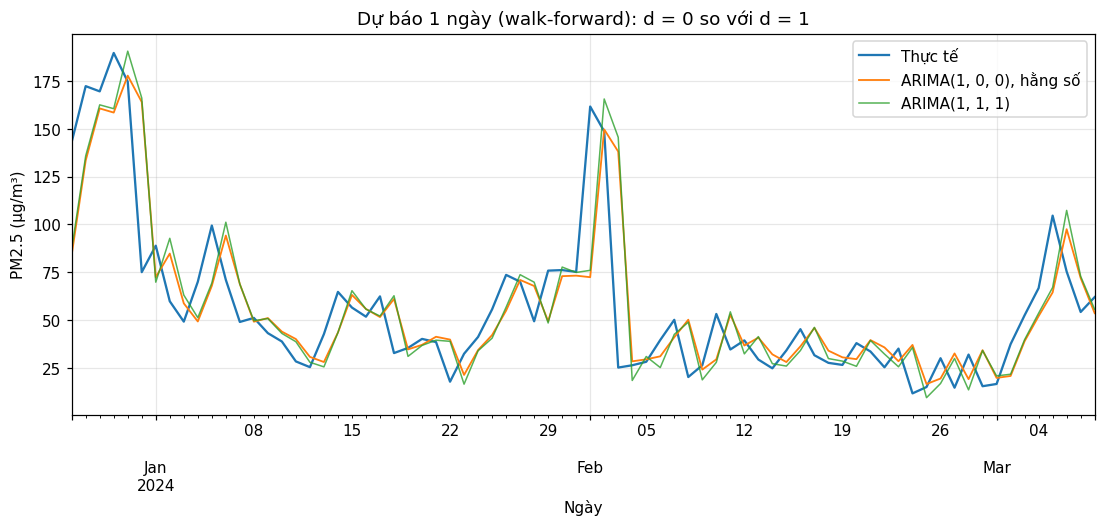

In [25]:
fig, ax = plt.subplots(figsize=(12, 4.5))
test.plot(ax=ax, label="Thực tế", lw=1.5)
pred_arima0.plot(ax=ax, label="ARIMA%s, hằng số" % (ORDER0,), lw=1.2)
pred_arima.plot(ax=ax, label="ARIMA%s" % (ORDER,), lw=1.0, alpha=0.8)
ax.set_title("Dự báo 1 ngày (walk-forward): d = 0 so với d = 1")
ax.set_xlabel("Ngày")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.show()

**Nhận xét biểu đồ dự báo 1 ngày: d = 0 so với d = 1**

- **Hai đường vẫn trễ một ngày so với thực tế:** đường ARIMA(1,0,0) (cam) và ARIMA(1,1,1) (xanh lá) đều chỉ phản ứng sau khi PM2.5 đã đổi, ví dụ đỉnh cuối tháng 12 và đợt tăng vọt đầu tháng 2. Đổi d không giúp mô hình báo trước được các điểm đảo chiều.
- **Đường d = 0 bị kéo về mức trung bình:** ở các đỉnh cao, d = 0 thấp hơn d = 1 (đỉnh cuối tháng 12: khoảng 178 so với khoảng 190; đỉnh đầu tháng 2: khoảng 150 so với khoảng 166), còn ở các đáy thấp thì cao hơn một chút. Lý do là hệ số AR = 0,89 < 1 nên mô hình luôn co giá trị dự báo về mức trung bình khoảng 49 µg/m³, trong khi d = 1 gần như chép lại giá trị hôm qua.
- **Tác động lên sai số:** việc co về trung bình làm giảm sai lệch ở các ngày đột biến (đợt giảm mạnh ngay sau đỉnh đầu tháng 2 sai ít hơn một chút) và nhiều ngày ổn định, nên MAE giảm từ 17,88 xuống 16,73 (khoảng 6%). Sự khác biệt giữa hai đường nhìn chung nhỏ, chênh lệch chỉ khoảng 1 µg/m³.
- **Mức ý nghĩa:** d = 0 sai ít hơn d = 1 ở 39/74 ngày, Wilcoxon p = 0,059 (sát ngưỡng 0,05); so với "hôm qua" p = 0,108. Đây là xu hướng cải thiện, chưa phải bằng chứng chắc chắn.


In [26]:
# Dự báo 1 đến 7 ngày với mô hình d = 0 (cùng các mốc như mục X)
err0 = []
for i in range(len(test) - H + 1):
    t = n0 + i
    f0 = ARIMA(values[:t], order=ORDER0, trend="c").fit().forecast(H)
    err0.append(np.abs(values[t:t + H] - f0))

mae_h0 = mae_h.copy()
mae_h0["ARIMA d=0"] = np.mean(err0, axis=0)
mae_h0.round(2)

,ARIMA,Hôm qua,Trung bình train,ARIMA d=0
Số ngày dự báo trước,,,,
1,17.69,17.18,27.71,16.49
2,24.87,24.60,26.38,23.63
3,26.74,27.14,24.82,24.74
4,28.88,30.41,23.87,26.83
5,29.96,32.06,22.19,26.51
6,29.35,31.97,20.42,24.10
7,32.20,34.87,20.22,24.92


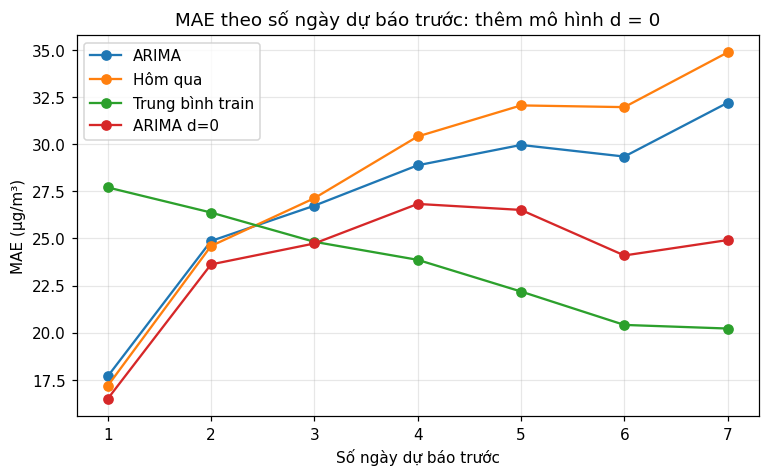

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))
mae_h0.plot(ax=ax, marker="o")
ax.set_title("MAE theo số ngày dự báo trước: thêm mô hình d = 0")
ax.set_xlabel("Số ngày dự báo trước")
ax.set_ylabel("MAE (µg/m³)")
plt.show()

**Nhận xét biểu đồ MAE theo số ngày dự báo trước (có thêm d = 0)**

- **ARIMA d = 0 (đỏ) thấp hơn ARIMA d = 1 (xanh dương) và "hôm qua" (cam) ở mọi mốc từ 1 đến 7 ngày.** Ví dụ ngày 1: 16,5 so với 17,7 và 17,2; ngày 7: 24,9 so với 32,2 và 34,9.
- **Sai số tăng chậm hơn khi dự báo xa:** từ ngày 1 đến ngày 7, d = 0 tăng khoảng 8,4 µg/m³ (16,5 → 24,9), còn d = 1 tăng khoảng 14,5 (17,7 → 32,2). Đường d = 0 gần như phẳng từ ngày 4 trở đi (26,8; 26,5; 24,1; 24,9) vì dự báo dần hồi về mức trung bình thay vì trôi theo giá trị gần nhất. Các dao động nhỏ sau ngày 4 không nên diễn giải vì chỉ có 68 mốc.
- **So với baseline trung bình train (xanh lá):** d = 0 tốt hơn ở ngày 1–2 (16,5 và 23,6 so với 27,7 và 26,4) và gần như bằng ở ngày 3 (24,7 so với 24,8). Từ ngày 4 trở đi baseline trung bình thấp hơn (ngày 7: 20,2 so với 24,9). Sau khoảng 3 ngày, lịch sử PM2.5 gần như không còn giúp dự báo tốt hơn so với đoán theo mức trung bình. Lưu ý đường trung bình giảm một phần do tập ngày được chấm thay đổi theo từng mốc (xem nhận xét ở mục X).
- **Kết luận:** trong các biến thể ARIMA đã thử, d = 0 (kèm hằng số) cho kết quả tốt nhất ở mọi số ngày dự báo, và là lựa chọn hợp lý nhất cho dự báo 1–3 ngày. Từ 4 ngày trở lên, cần thông tin ngoài lịch sử PM2.5 (ví dụ thời tiết) mới có hy vọng vượt cách đoán bằng mức trung bình. Kết quả chỉ dựa trên một tập test trong mùa đông, nên chưa thể khẳng định d = 0 luôn tốt hơn.

# XIII. Giải thích các chỉ số dùng trong notebook

### 1. Chỉ số đo sai số dự báo (mục VI, IX, X)

| Chỉ số | Công thức | Ý nghĩa | Cách đọc |
|---|---|---|---|
| **MAE** (sai số tuyệt đối trung bình) | $\frac{1}{n}\sum \lvert y_t-\hat y_t\rvert$ | Trung bình mỗi ngày dự báo lệch bao nhiêu µg/m³ so với thực tế | Càng thấp càng tốt. Ví dụ MAE = 17,88 nghĩa là trung bình mô hình lệch khoảng 18 µg/m³. Dễ hiểu, ít bị ảnh hưởng bởi vài ngày cực đoan |
| **RMSE** (căn bậc hai sai số bình phương trung bình) | $\sqrt{\frac{1}{n}\sum (y_t-\hat y_t)^2}$ | Giống MAE nhưng bình phương sai số trước khi lấy trung bình, nên phạt nặng các ngày sai lớn | Luôn ≥ MAE. Khoảng cách RMSE − MAE càng lớn thì càng có nhiều ngày sai rất lớn. Ví dụ baseline "hôm qua": MAE 17,48 nhưng RMSE 26,99 |
| **% cải thiện so với baseline** | $\frac{MAE_{base}-MAE_{mô\ hình}}{MAE_{base}}\times 100$ | Mô hình tốt hơn baseline bao nhiêu phần trăm | Dương: tốt hơn. Âm: kém hơn (ARIMA so với "hôm qua": −2,3%) |
| **Số ngày sai ít hơn** | Đếm số ngày $\lvert y_t-\hat y^{ARIMA}_t\rvert < \lvert y_t-\hat y^{base}_t\rvert$ | Mô hình thắng baseline ở bao nhiêu ngày | Gần 50% (36/74) nghĩa là hai mô hình gần như ngang nhau |

Khi hai mô hình có MAE và RMSE xếp hạng khác nhau (ARIMA có MAE cao hơn nhưng RMSE thấp hơn "hôm qua"), nghĩa là chúng khác nhau về loại sai số chứ không có mô hình nào vượt trội rõ rệt.

### 2. Chỉ số chọn mô hình (mục VII)

| Chỉ số | Ý nghĩa | Cách đọc |
|---|---|---|
| **AIC** | $2k-2\ln L$: đo độ khớp của mô hình với dữ liệu train ($L$: độ hợp lý), cộng phạt theo số tham số $k$ | Càng thấp càng tốt. Giá trị tuyệt đối không có ý nghĩa, chỉ so sánh giữa các mô hình trên cùng dữ liệu và cùng d. Chênh lệch dưới khoảng 2 coi như tương đương (ARIMA(1,1,1): 2514,72 so với 2515,27 của ARIMA(1,1,2)) |
| **BIC** | $k\ln n-2\ln L$: giống AIC nhưng phạt số tham số nặng hơn | Thiên về mô hình đơn giản hơn AIC. Nếu AIC và BIC cùng chọn một mô hình (như ở đây) thì lựa chọn khá vững |
| **MAE train** | MAE tính trên chính dữ liệu đã dùng để huấn luyện | Chỉ để tham khảo. Mô hình càng phức tạp thì MAE train càng thấp nhưng chưa chắc dự báo tốt hơn, nên không dùng để chọn mô hình |

### 3. Kiểm định thống kê

Với mọi kiểm định dưới đây, **p-value** là xác suất thấy được kết quả như đã quan sát (hoặc cực đoan hơn) *nếu giả thuyết H0 đúng*. Quy ước: p < 0,05 thì bác bỏ H0.

| Kiểm định | Mục | H0 | Kết quả | Kết luận |
|---|---|---|---|---|
| **ADF** (thống kê ADF, p) | IV | Chuỗi không dừng | Chuỗi gốc p = 0,0905; sau sai phân p ≈ 0 | Chuỗi gốc chưa dừng, sau sai phân dừng, nên d = 1. Thống kê ADF càng âm thì càng nghiêng về dừng |
| **Ljung-Box** | VIII | Phần dư không tự tương quan đến lag m | Lag 10: p = 0,68; lag 20: p = 0,021 | p > 0,05 là đạt. Lag 10 đạt, lag 20 chưa đạt (chủ yếu do lag 12) |
| **Shapiro-Wilk** | VIII | Phần dư có phân phối chuẩn | p ≈ 0 | Phần dư không chuẩn (đuôi dày) |
| **Wilcoxon** (cặp) | IX | Sai số hằng ngày của hai mô hình không khác nhau | p = 0,30 | Chưa đủ bằng chứng rằng ARIMA khác baseline "hôm qua" |

### 4. Các đại lượng khác

- **Độ lệch (skewness):** đo mức bất đối xứng của phân phối. Bằng 0 là đối xứng, dương là đuôi phải dài, âm là đuôi trái dài. Phần dư có độ lệch ≈ 0 (đối xứng) nhưng đuôi dày ở cả hai phía.
- **Vùng xanh trong ACF/PACF:** khoảng tin cậy 95% quanh 0. Cột nằm trong vùng xanh coi như không khác 0.
- **Hệ số mô hình (bảng `summary`):** `ar.L1` là hệ số của giá trị hôm qua sau sai phân, `ma.L1` là hệ số của sai số hôm qua. `sigma2` là phương sai của phần dư (≈ 314,5, tức độ lệch chuẩn khoảng 17,7 µg/m³, cùng bậc với MAE).
- **Sai phân bậc 1:** $\Delta y_t=y_t-y_{t-1}$, tức mức thay đổi PM2.5 so với hôm trước.